### Libraries
Make sure to download SimilarityHelper and TopObject first. Currently available from https://github.com/CReM-BU/Vilker_Helper_Files/tree/main/scTOP/scripts. Commit used for this paper (11/20/26) is tagged: K17-submission-v1

In [1]:
import pandas as pd
import plotly.io as pio
import sys
import os
os.chdir('/restricted/projectnb/crem-trainees/Kotton_Lab/Eitan/Lauren/KRT17_Reporter/scripts') # Replace with your path to this directory
sys.path.append('/restricted/projectnb/crem-trainees/Kotton_Lab/Eitan/Vilker_Helper_Files/scTOP/scripts') # Replace with path to scTOP code
%load_ext autoreload
%autoreload 1
%aimport SimilarityHelper
%aimport TopObject
pio.renderers.default = 'notebook'

In [2]:
HaberMAP = TopObject.loadBasis(file="../objects/HaberMAP500ANOVA02.csv",
            basisKeep=["AT2", "AT1", "Basal", "Ciliated", "Goblet", "Secretory", "KRT5-/KRT17+"]
)

Loaded basis!


### Setup steps
1. Download the AnnData (.h5ad) object containing the results
2. Place it in the objects folder or desired location
3. Change the file path in DatasetCollection.csv to the path to the h5ad

In [3]:
# Don't forget to change the file path to the h5ad in DatasetCollection.csv!
datasetCollection = "../objects/DatasetCollection.csv"
ayers = TopObject.TopObject("Ayers_06_24_25", datasetCollection=datasetCollection, skipProcess=False)
ayers.metadata

Setting AnnData object...
Setting AnnData...
Setting metadata and df...
Processing scTOP data...
Done processing!
Finished setup!


,orig.ident,nCount_RNA,nFeature_RNA,percent.mito,nCount_SCT,nFeature_SCT,SCT_snn_res.1.5,SCT_snn_res.1.25,SCT_snn_res.1,SCT_snn_res.0.75,...,DS_Alveolar_top50,DS_Peribronchial_top50,DS_Pericyte_top50,DS_Smoothmuscle_top50,top50_distal,top50_proximal,Fibrotic_markers,sample,TGFB.subclustered,subcluster_names
AAACCCTGTTGCATGT-1,KD_AL_OCM_1,1160.0,824,0.431034,8719.0,3111,7,9,12,12,...,0.051555,0.158549,-0.003502,0.058390,0.001887,-0.022164,-0.054978,iAT2s CK+DCI,0,iAT1
AAACGATGTAACGCTT-1,KD_AL_OCM_1,9786.0,3693,3.964848,10229.0,3672,3,3,4,4,...,0.090532,0.065302,0.001816,-0.108044,-0.051608,0.112941,-0.364186,iAT2s CK+DCI,3,iAT2
AAACGATGTAGTCAGA-1,KD_AL_OCM_1,8390.0,3317,11.096544,9939.0,3290,5,5,8,8,...,0.044441,0.225597,0.004183,-0.004789,0.119180,-0.065431,-0.239712,iAT2s CK+DCI,3,iAT2
AAACGATGTCATTAGC-1,KD_AL_OCM_1,7328.0,3029,7.014192,9891.0,3018,5,5,8,8,...,0.065374,-0.025109,0.093421,0.021200,-0.062860,0.001614,-0.236135,iAT2s CK+DCI,3,iAT2
AAACGATGTCCATCTC-1,KD_AL_OCM_1,7058.0,3330,3.485407,9613.0,3317,22,21,17,15,...,-0.068276,0.058131,-0.028161,0.046828,0.031566,-0.030657,-0.546011,iAT2s CK+DCI,8,PNEC-like
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGTGTTGAGGATAGGT-1,KD_AL_OCM_4,7429.0,2951,10.216718,10084.0,2959,1,0,2,3,...,-0.053260,-0.029090,-0.059911,0.140105,-0.070606,-0.056713,-0.174943,iBCs PneumacultEx,5,iBC 2
TGTGTTGAGGATCTCA-1,KD_AL_OCM_4,22556.0,5893,9.035290,11966.0,4861,9,10,9,10,...,0.080089,0.029638,-0.124892,0.027881,-0.055411,-0.116010,-0.195056,iBCs PneumacultEx,6,Differentiating Airway
TGTGTTGAGTAACCTG-1,KD_AL_OCM_4,8101.0,3034,10.615973,10085.0,3036,0,1,0,1,...,0.002453,0.071922,0.016410,0.137420,-0.113732,-0.030080,0.451311,iBCs PneumacultEx,4,iBC 1
TGTGTTGAGTGAGGAT-1,KD_AL_OCM_4,15066.0,4532,12.080181,11897.0,4515,9,10,9,10,...,0.057892,-0.049418,-0.066574,-0.010816,0.043567,-0.001803,-0.336585,iBCs PneumacultEx,6,Differentiating Airway


In [4]:
ayers.annotations.value_counts()

subcluster_names
iAT1                        3579
Proliferating (distal)      2258
iAT2                        2081
iBC 1                       1741
iBC 2                       1315
SOX high TGFB-treated       1137
Differentiating Airway      1035
Proliferating (proximal)     930
KRT5-/KRT17+                 900
PreKRT5-/KRT17+              671
PNEC-like                    231
Non-lung contaminant          21
Name: count, dtype: int64

In [5]:
ayers.project(HaberMAP, "HaberMAP")

Projecting Ayers_06_24_25 onto HaberMAP basis...
Finished projecting! 1183 genes were in both the source and basis.


,AAACCCTGTTGCATGT-1,AAACGATGTAACGCTT-1,AAACGATGTAGTCAGA-1,AAACGATGTCATTAGC-1,AAACGATGTCCATCTC-1,AAACGATGTTCGTGGC-1,AAACGATGTTGAGCCC-1,AAACGATGTTTCGGTG-1,AAACTCCGTTAGTCCG-1,AAACTCCGTTCGCCAA-1,...,TGTGGTCAGATTACCG-1,TGTGGTCAGCAATCGC-1,TGTGGTCAGGATGGTG-1,TGTGGTCAGGATTAAG-1,TGTGTTGAGCGAATGG-1,TGTGTTGAGGATAGGT-1,TGTGTTGAGGATCTCA-1,TGTGTTGAGTAACCTG-1,TGTGTTGAGTGAGGAT-1,TGTGTTGAGTTAGTCG-1
AT1,0.037736,-0.013560,0.023984,0.000760,0.008145,0.007342,0.011685,0.009386,-0.008334,0.055064,...,-0.015845,0.017476,0.017032,-0.007423,-0.035728,-0.014719,-0.008523,0.015191,0.001428,0.016296
AT2,0.078461,0.087856,0.096691,0.069766,0.046951,0.099534,0.082879,0.091066,0.100103,0.082053,...,0.064478,0.048978,0.066730,0.068703,0.063691,0.050452,0.076473,0.059708,0.070159,0.056547
Basal,0.067464,0.090428,0.067371,0.057150,0.089741,0.078212,0.042553,0.050572,0.097649,0.062827,...,0.059529,0.206658,0.229853,0.198985,0.195086,0.170947,0.036967,0.184155,0.090968,0.177484
Ciliated,-0.113789,-0.105120,-0.135550,-0.125305,-0.058454,-0.106715,-0.108315,-0.100006,-0.105344,-0.141017,...,-0.133062,-0.126894,-0.137140,-0.135094,-0.116943,-0.123469,-0.135419,-0.119095,-0.158063,-0.138974
Goblet,-0.068198,-0.056605,-0.065614,-0.039963,-0.055248,-0.070700,-0.051893,-0.055931,-0.037675,-0.048894,...,-0.021656,-0.028818,-0.011297,0.005464,-0.037884,-0.042417,0.018795,-0.027459,0.013592,-0.026506
Secretory,0.068196,0.052174,0.071812,0.041428,0.028932,0.053498,0.062247,0.051162,0.043782,0.060306,...,0.134540,-0.059569,-0.070823,-0.076999,-0.014877,0.043559,0.123099,-0.063537,0.098918,-0.015161
KRT5-/KRT17+,0.037291,0.039080,0.052069,0.101762,0.019667,0.037688,0.066570,0.056927,0.011422,0.045410,...,0.021013,0.051158,0.048567,0.070362,0.054315,0.025547,0.026249,0.080193,0.001878,0.050666


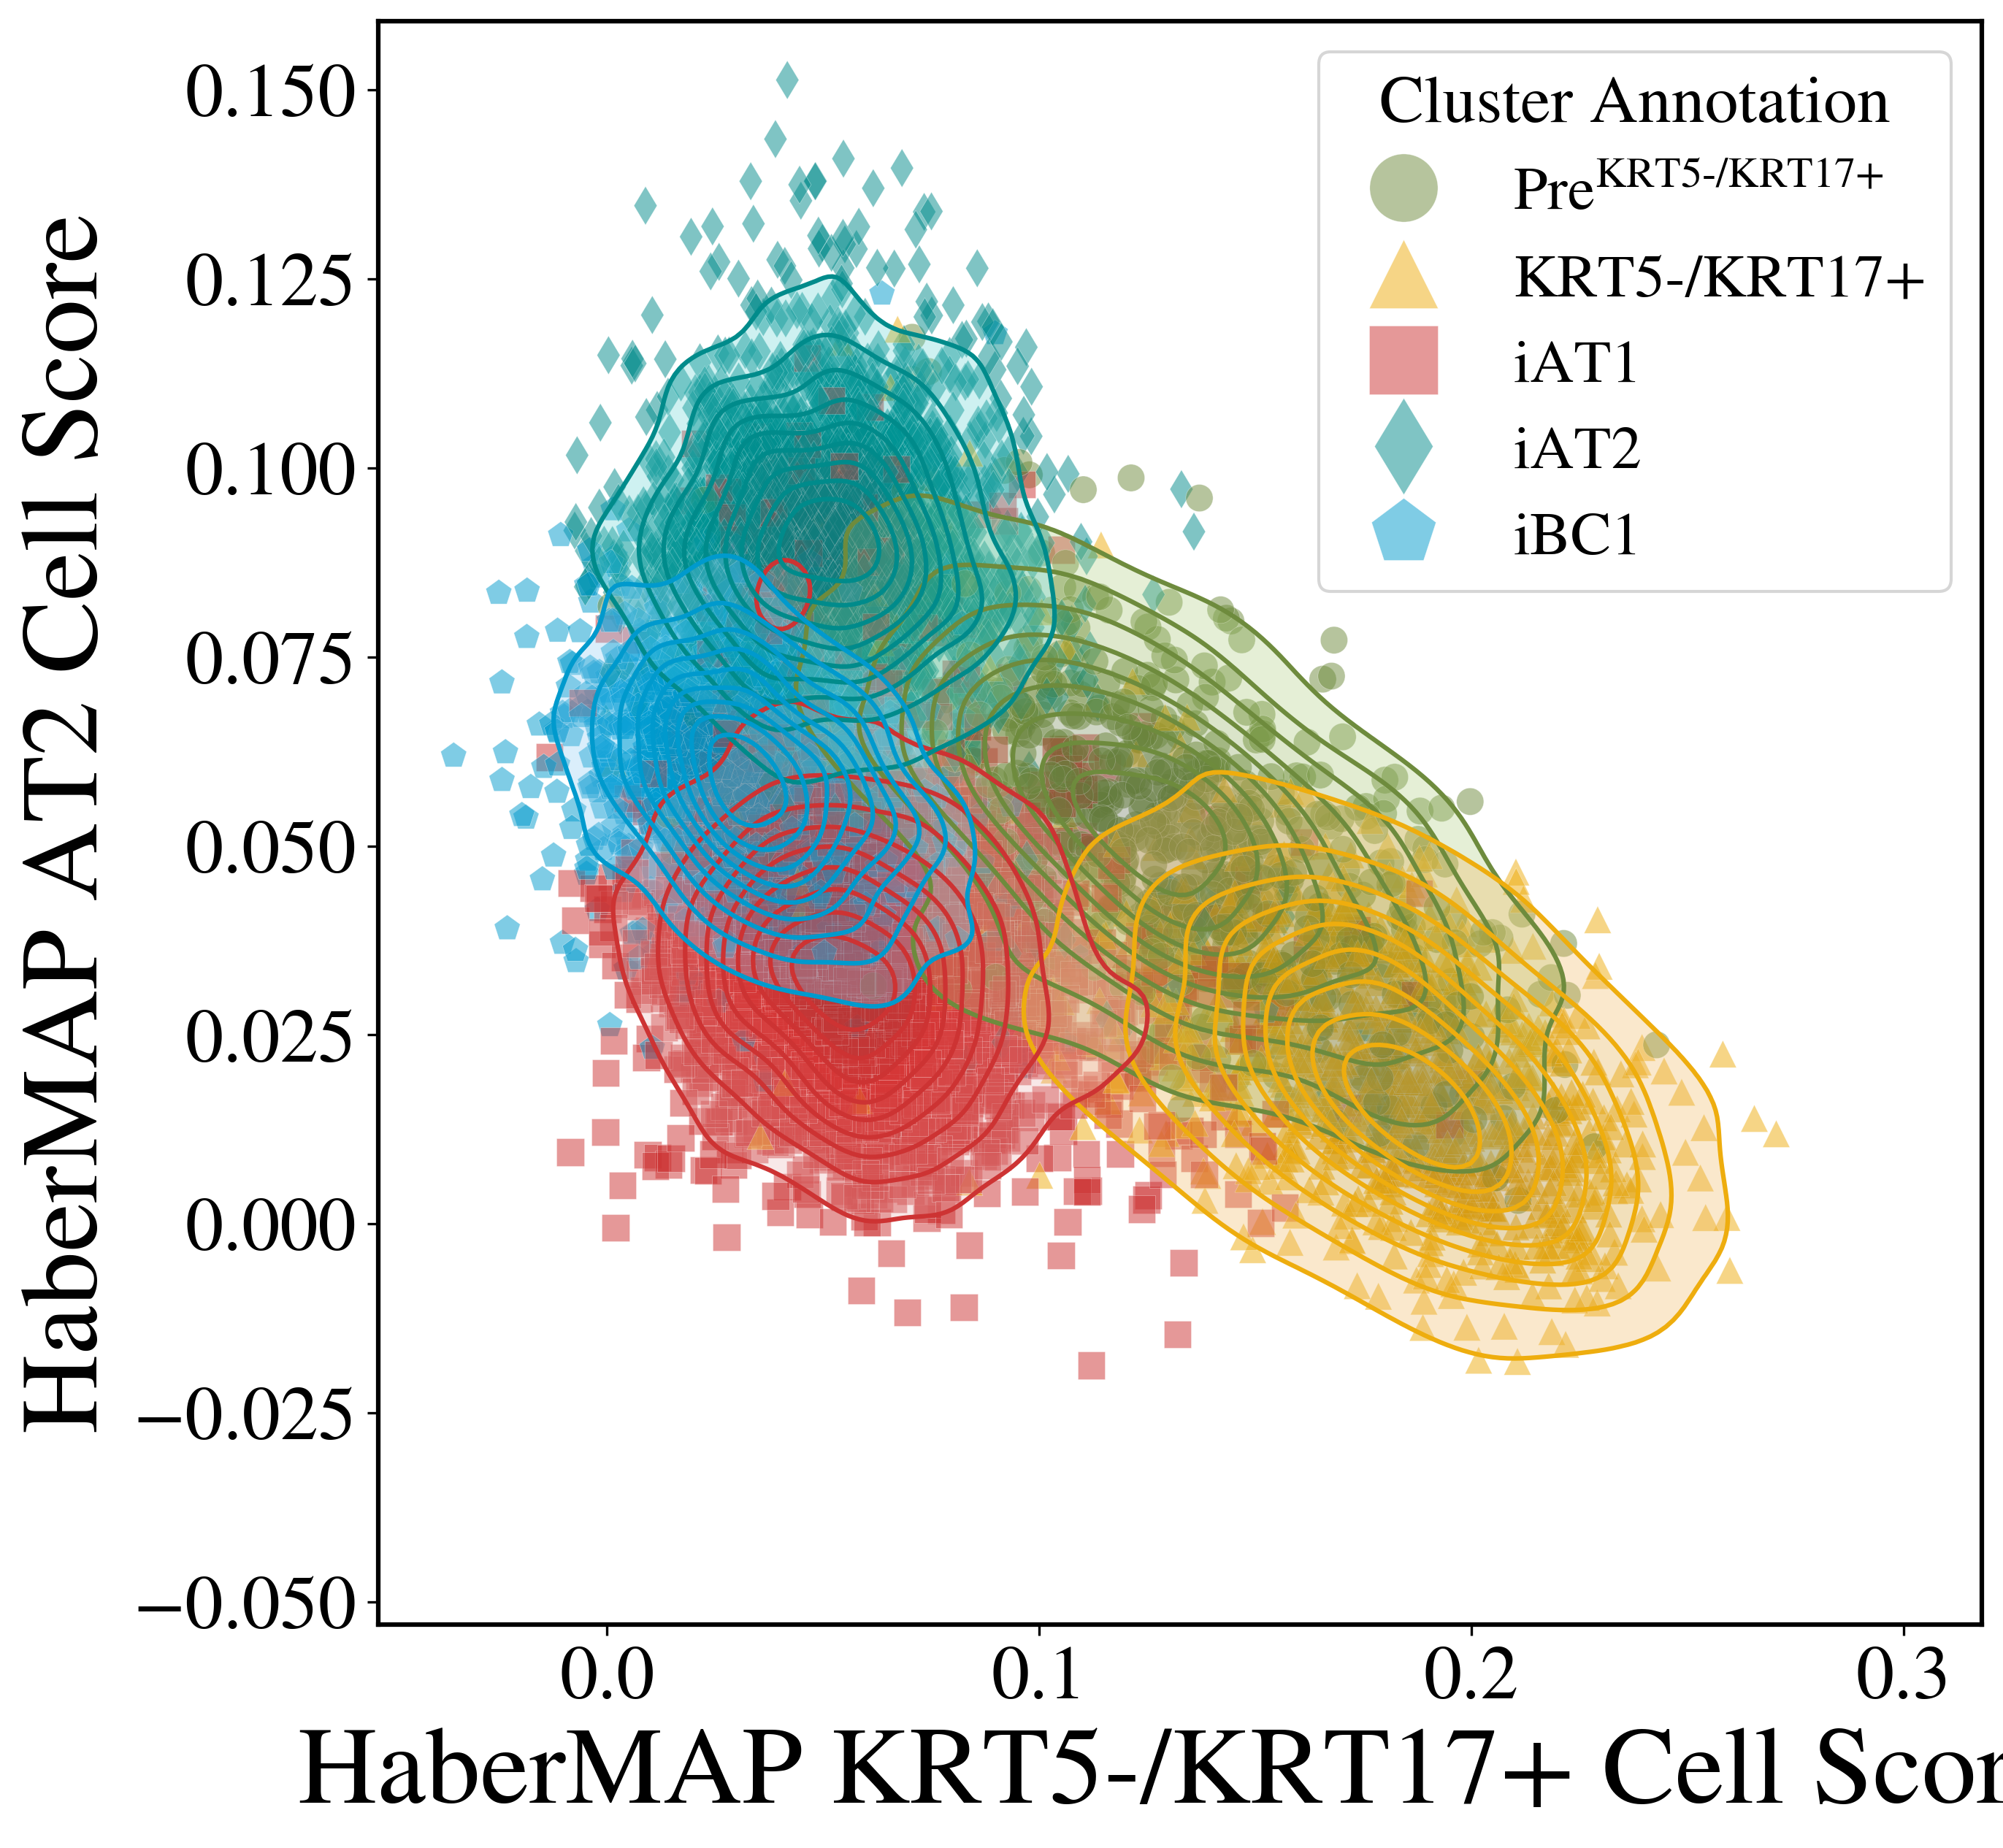

In [6]:
includeCriteria = ayers.annotations.isin(["iAT1", "iAT2", "PreKRT5-/KRT17+", "KRT5-/KRT17+", "iBC 1"])
ax = SimilarityHelper.plotTwo(ayers, "HaberMAP", "KRT5-/KRT17+", "AT2", 
    includeCriteria=includeCriteria, supervisedContour=True, labels=["PreKRT5-/KRT17+", "KRT5-/KRT17+", "iAT1", "iAT2", "iBC 1"],
    plotThreshold=False, legendReplacements={"PreKRT5-/KRT17+": r"Pre$\mathregular{^{KRT5\text{-}/KRT17\text{+}}}$", "iBC 1": "iBC1"},
    title='', legendTitle="Cluster Annotation", source="Lauren", DPI=300, outFile="../results/Fig 3G.pdf"
)

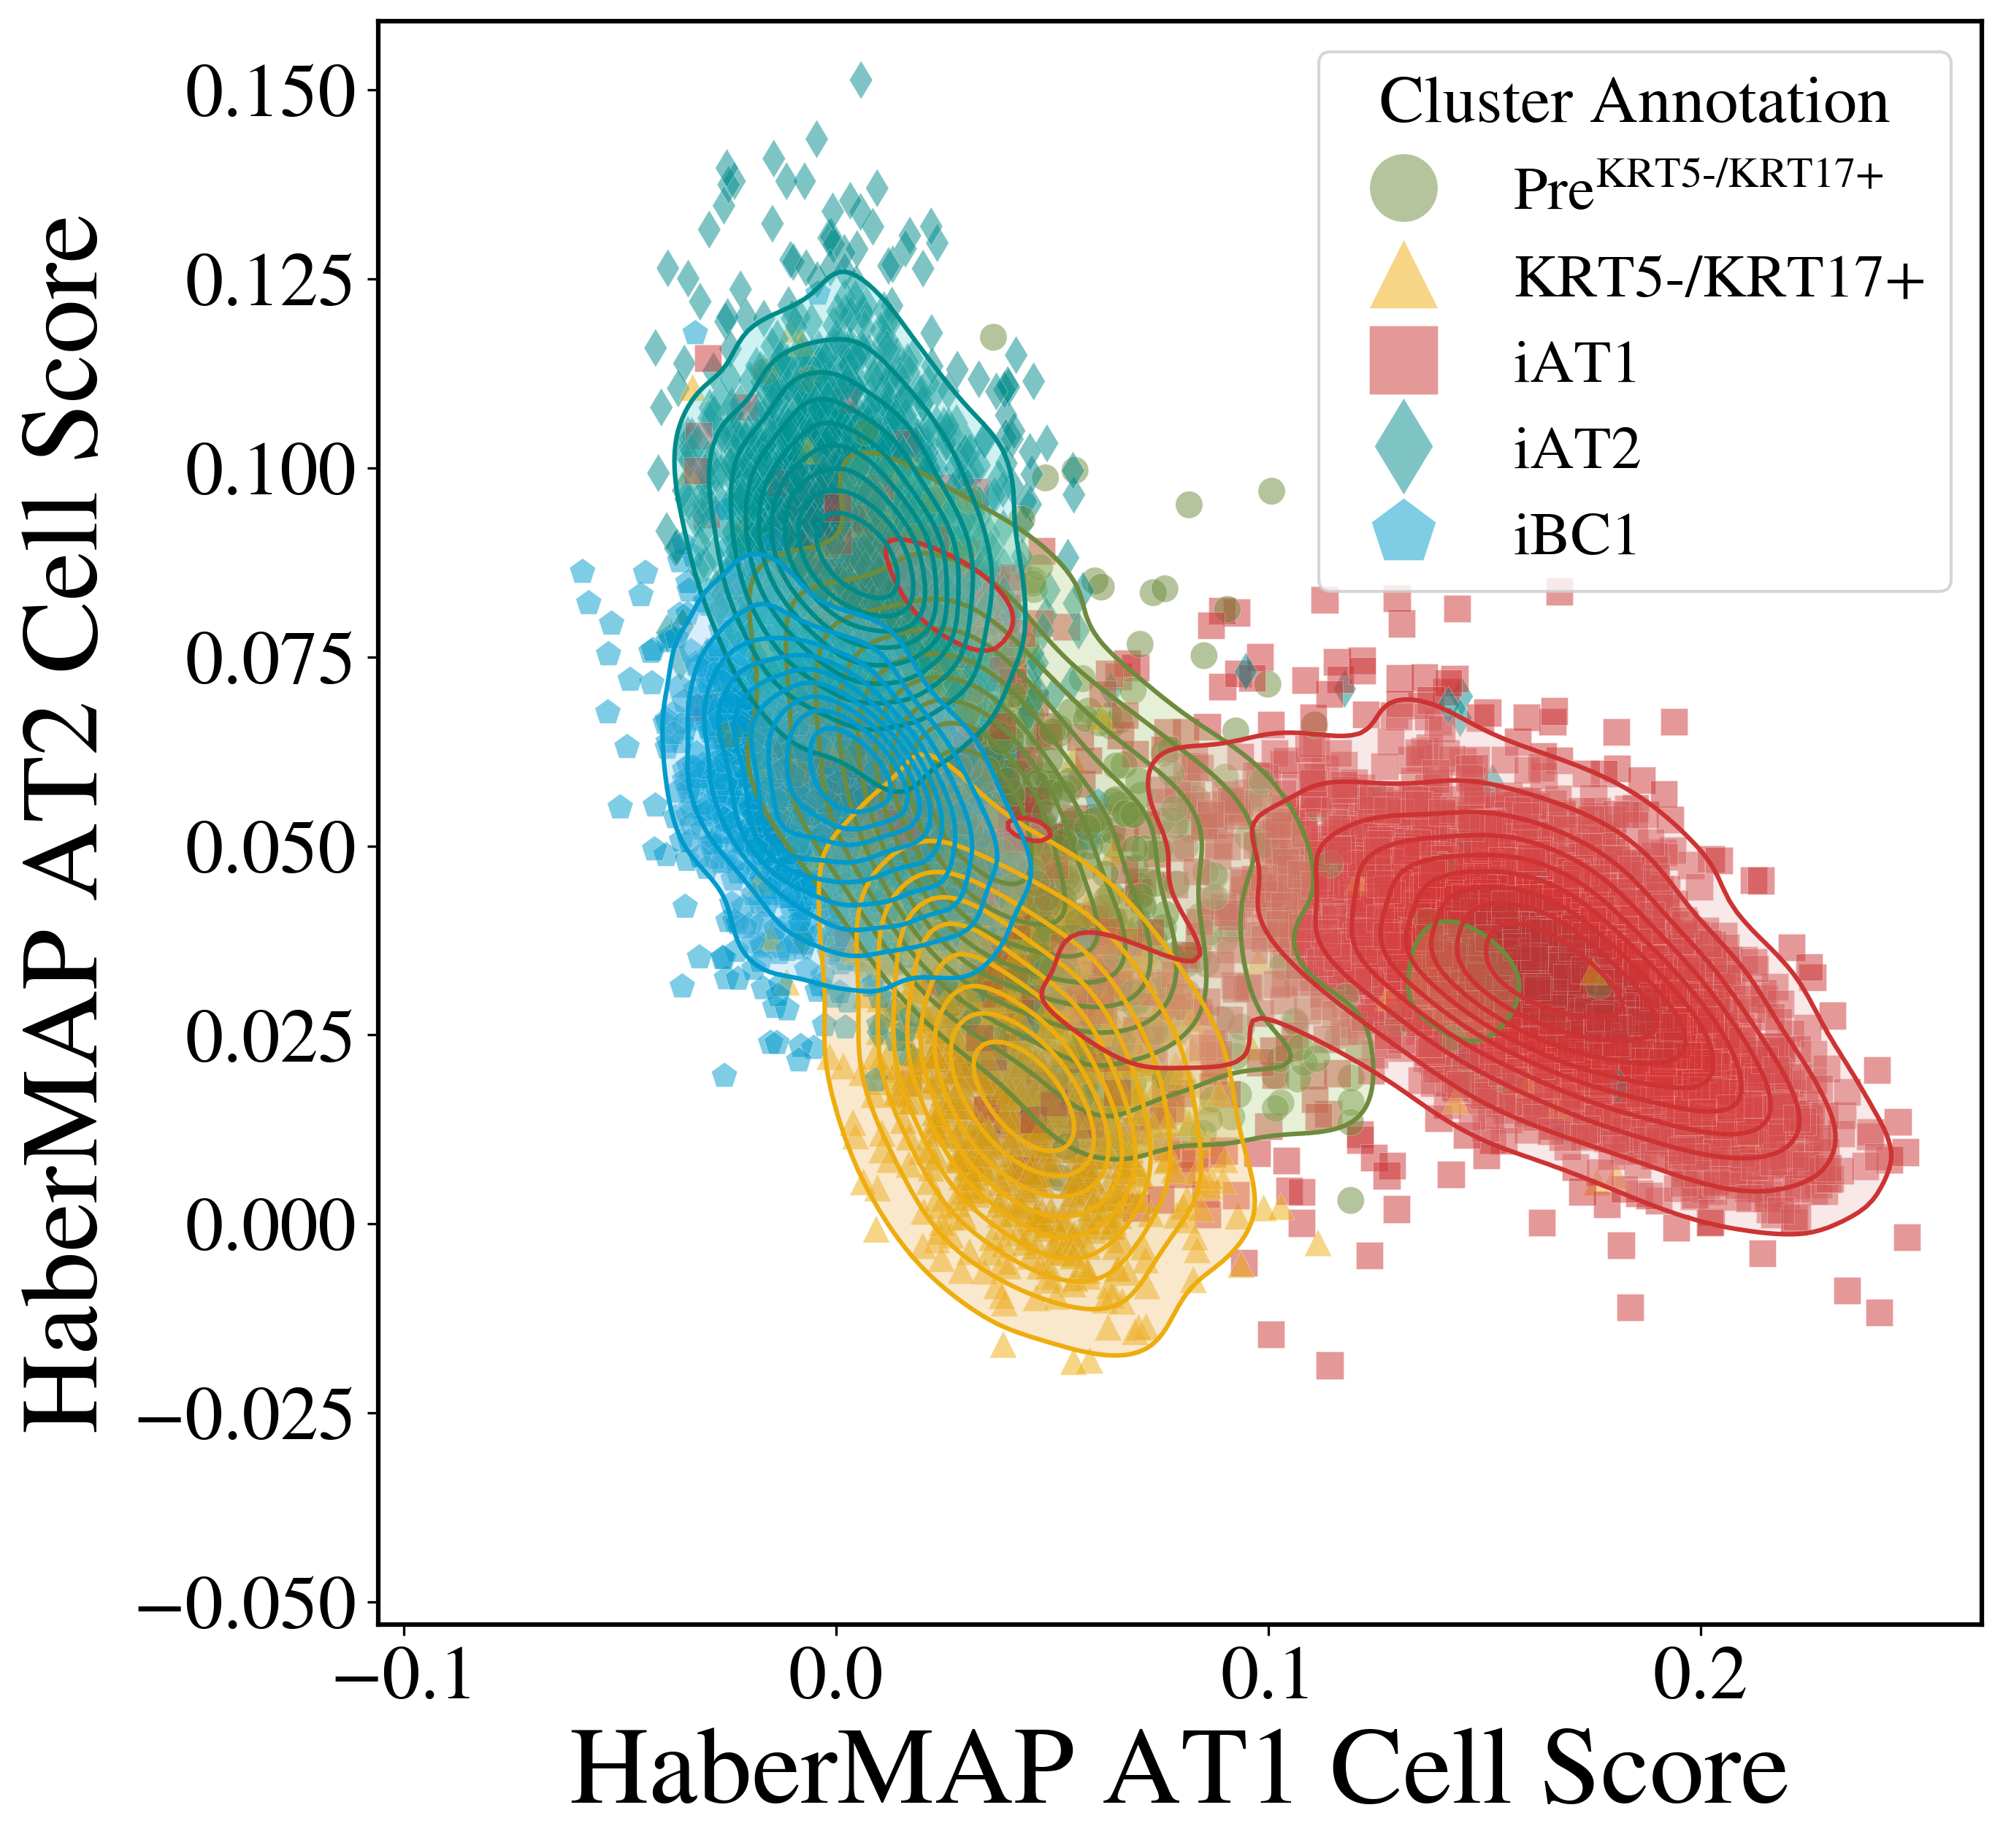

In [7]:
includeCriteria = ayers.annotations.isin(["iAT1", "iAT2", "PreKRT5-/KRT17+", "KRT5-/KRT17+", "iBC 1"])
ax = SimilarityHelper.plotTwo(ayers, "HaberMAP", "AT1", "AT2", 
    includeCriteria=includeCriteria, supervisedContour=True, labels=["PreKRT5-/KRT17+", "KRT5-/KRT17+", "iAT1", "iAT2", "iBC 1"],
    plotThreshold=False, legendReplacements={"PreKRT5-/KRT17+": r"Pre$\mathregular{^{KRT5\text{-}/KRT17\text{+}}}$", "iBC 1": "iBC1"},
    title='', legendTitle="Cluster Annotation", source="Lauren", DPI=300, outFile="../results/Fig 3H.pdf"
)

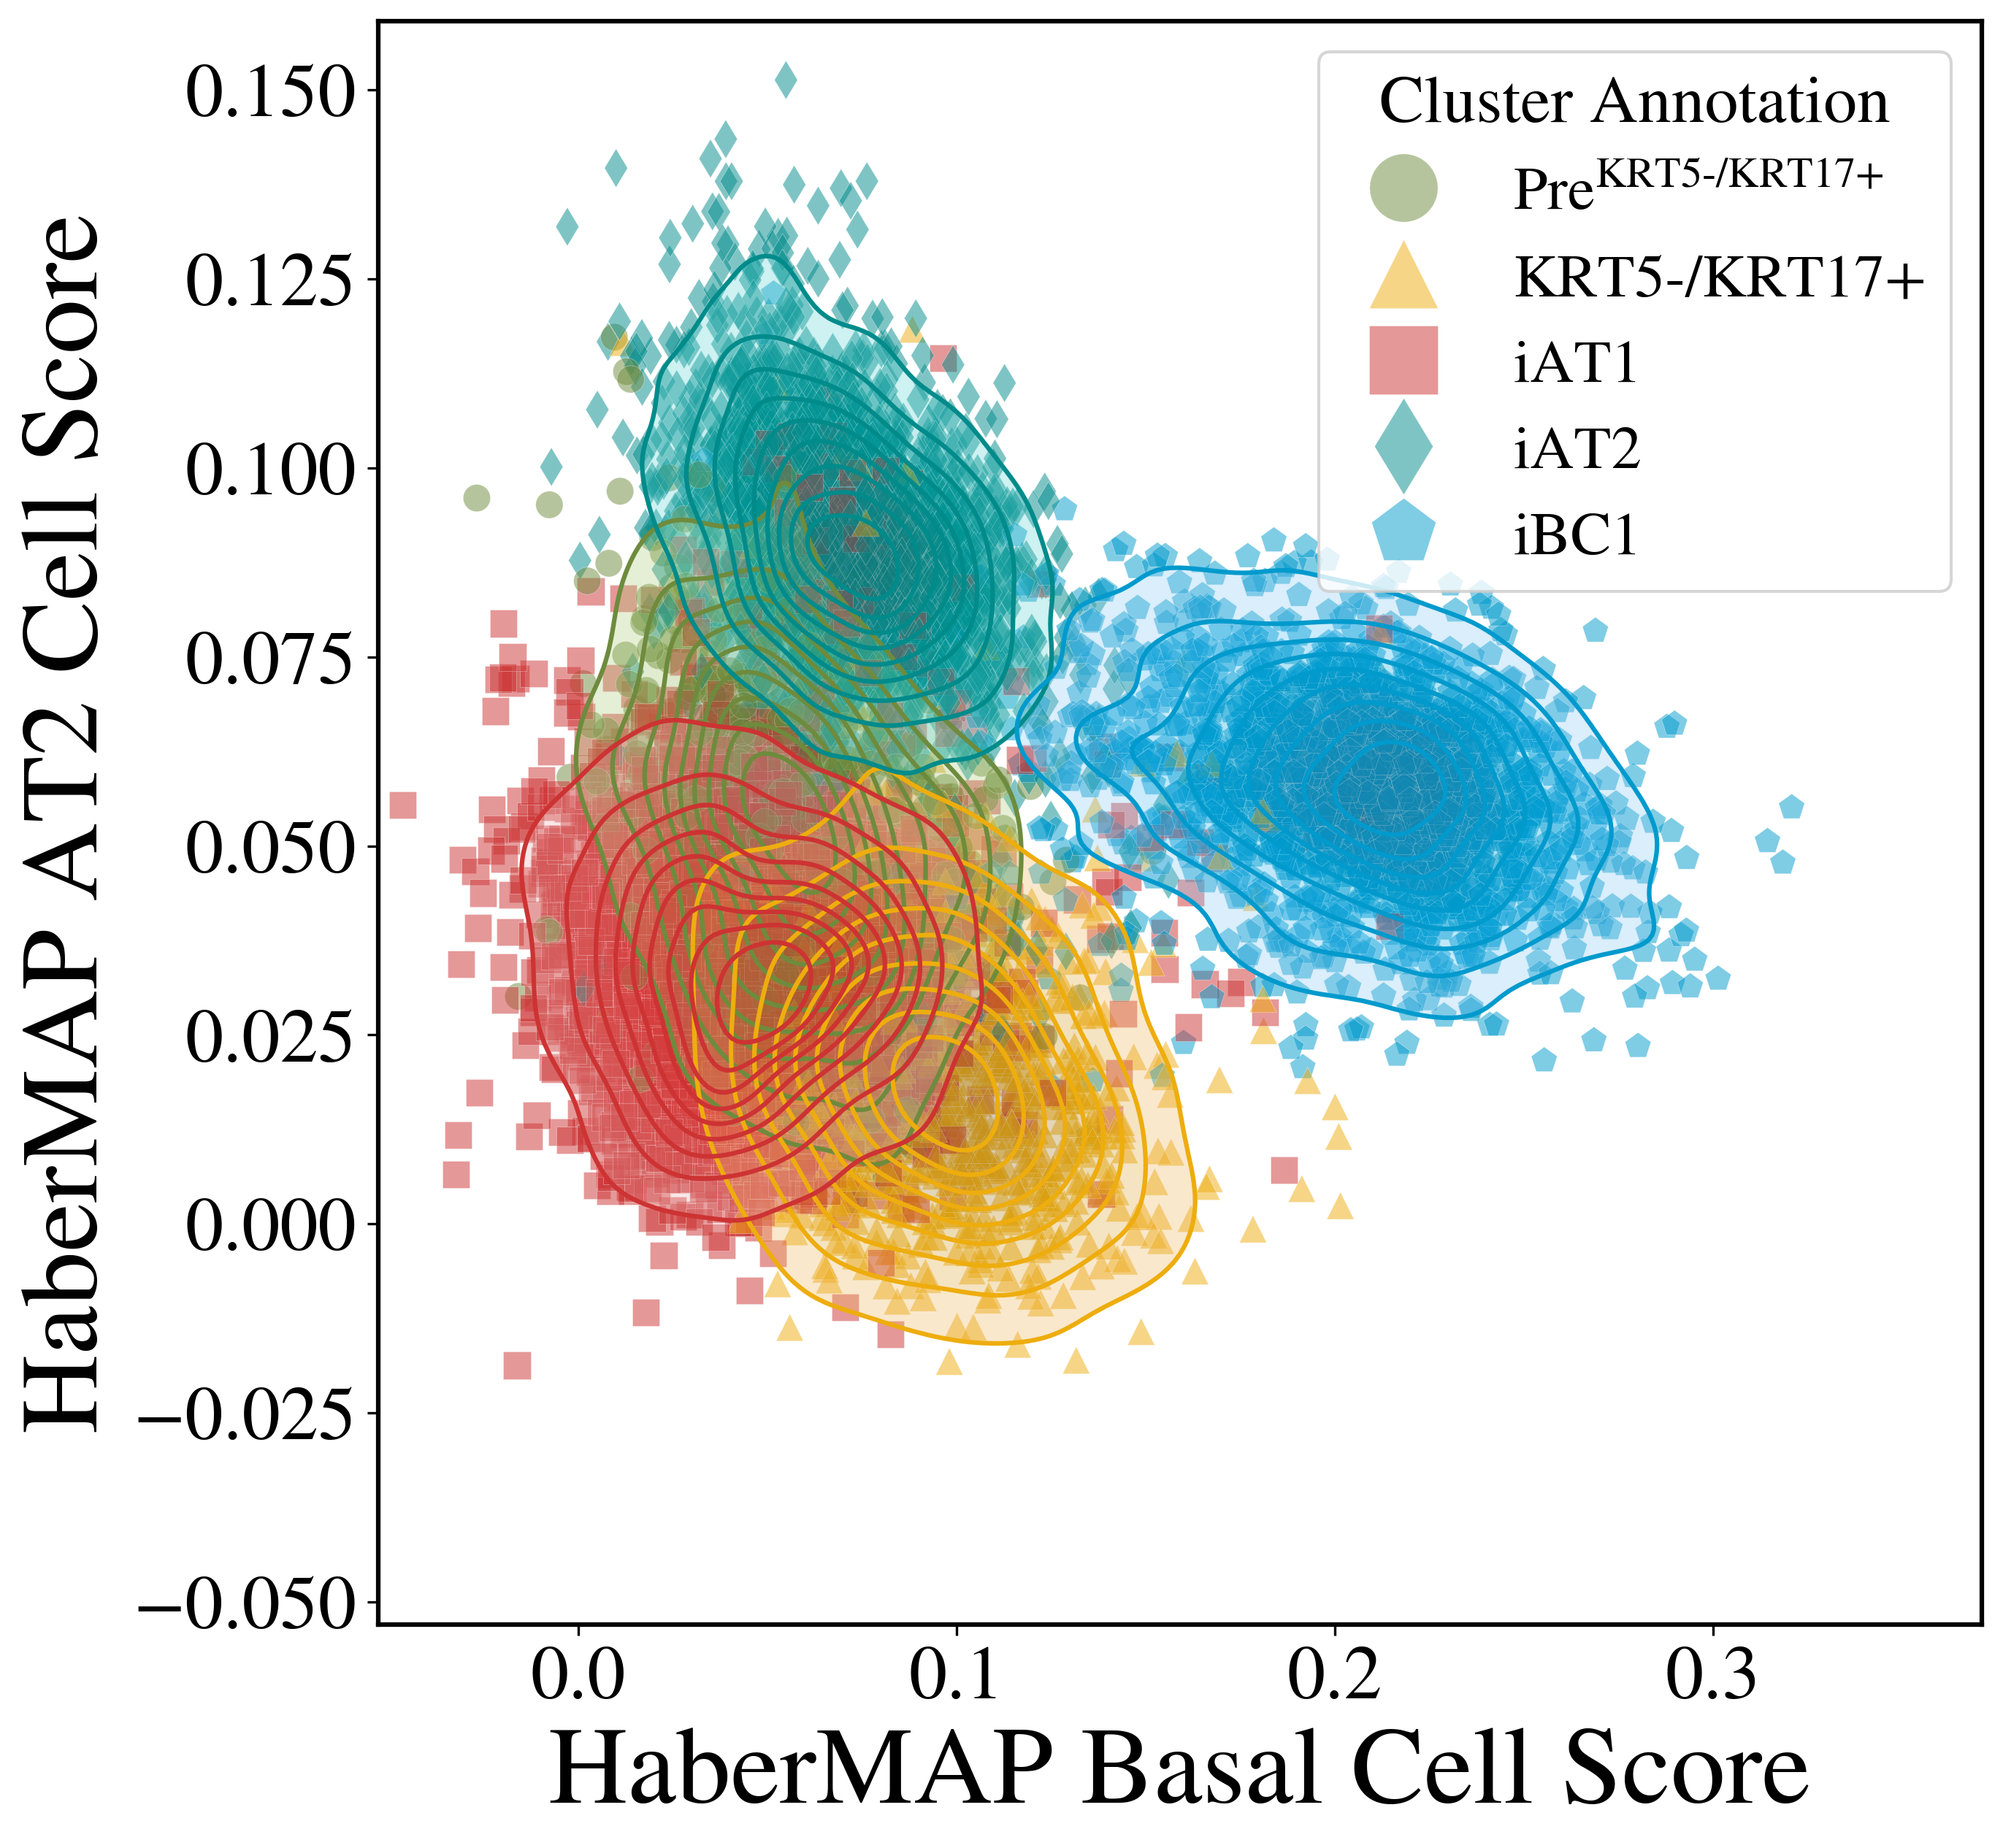

In [8]:
includeCriteria = ayers.annotations.isin(["iAT1", "iAT2", "PreKRT5-/KRT17+", "KRT5-/KRT17+", "iBC 1"])
ax = SimilarityHelper.plotTwo(ayers, "HaberMAP", "Basal", "AT2", 
    includeCriteria=includeCriteria, supervisedContour=True, labels=["PreKRT5-/KRT17+", "KRT5-/KRT17+", "iAT1", "iAT2", "iBC 1"],
    plotThreshold=False, legendReplacements={"PreKRT5-/KRT17+": r"Pre$\mathregular{^{KRT5\text{-}/KRT17\text{+}}}$", "iBC 1": "iBC1"},
    title='', legendTitle="Cluster Annotation", source="Lauren", DPI=300, outFile="../results/Fig S3H.pdf"
)